Monte Carlo Integration

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import myutils
import seaborn as sns


In [2]:
sns.set_style('whitegrid')

TRUE_VALUE = 0.8107993761730179

Analytic solution for $cos^2(x)$ = 0.8107993761730179

In [3]:
a, b = 0, 2
n = 1000

approximation, error = myutils.monte_carlo_integral(myutils.cos_sq, a, b, n)
print(f'Approximation of integral of[cos^2(x)], a=0, b=2 {approximation}')
print('Analytical solution: 0.8107993761730179')
print(f'Error: {error}')


Approximation of integral of[cos^2(x)], a=0, b=2 0.8058825382459481
Analytical solution: 0.8107993761730179
Error: 0.02307645604669136


[0.00072593 0.0007293  0.00073396 0.00073733 0.00074232 0.00074679
 0.00075021 0.00075564 0.00075957 0.00076373 0.00076865 0.00077308
 0.00077682 0.00078188 0.00078597 0.00079083 0.00079518 0.00079915
 0.00080462 0.0008093  0.0008135  0.00081883 0.00082341 0.00082789
 0.00083245 0.00083788 0.00084304 0.00084731 0.00085298 0.00085673
 0.0008627  0.00086714 0.00087236 0.00087774 0.00088187 0.00088756
 0.00089183 0.00089761 0.00090315 0.00090845 0.00091296 0.00091854
 0.00092394 0.00092878 0.00093539 0.00094014 0.00094481 0.00095087
 0.00095582 0.00096121 0.00096825 0.00097321 0.00097831 0.00098439
 0.00099037 0.00099626 0.00100104 0.00100702 0.00101262 0.00101792
 0.00102501 0.00103072 0.00103735 0.00104288 0.0010483  0.00105574
 0.00106019 0.00106687 0.0010723  0.00107898 0.00108472 0.00109132
 0.00109909 0.00110489 0.00111124 0.00111752 0.00112444 0.00113023
 0.00113656 0.00114383 0.00114996 0.00115679 0.00116283 0.00116929
 0.00117601 0.00118452 0.00118911 0.00119851 0.00120288 0.0012

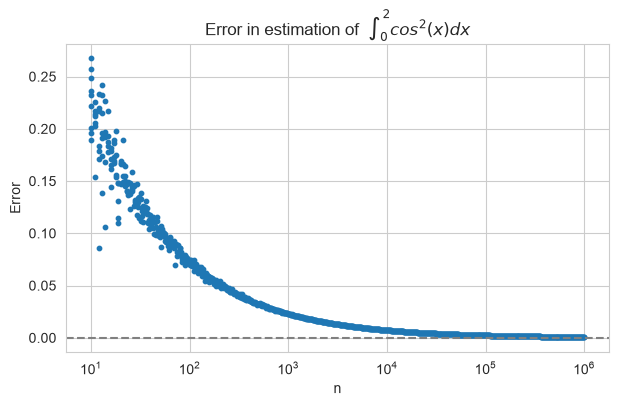

In [4]:
n = np.int64(np.logspace(1, 6, 1000))
mc_errors = np.array([myutils.monte_carlo_integral(myutils.cos_sq, a, b, i)[1] for i in n])

fig = plt.figure(figsize=(7, 4))
plt.title(r'Error in estimation of  $\int_{0}^{2} cos^2(x) dx$')

print(np.sort(mc_errors))
plt.xlabel('n')
plt.ylabel('Error')

plt.axhline(0, c='grey', ls='--')

plt.scatter(n, mc_errors, s=10)
plt.xscale('log')



Lets compare with trapezium rule

In [6]:
a, b = 0, 2
n = 1000

myutils.trapezium_rule(myutils.cos_sq, a, b, n, 'mea', TRUE_VALUE)



(np.float64(0.8099888293169308), np.float64(0.0008105468560870577))

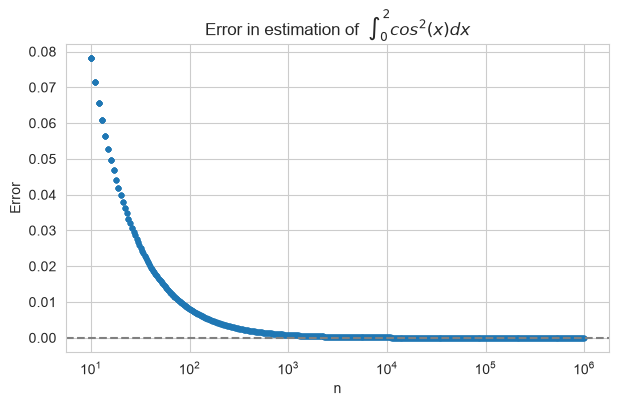

In [8]:
n = np.int64(np.logspace(1, 6, 1000))
trapezia_errors = np.array([myutils.trapezium_rule(myutils.cos_sq, a, b, i, 'mea', TRUE_VALUE)[1] for i in n])


fig = plt.figure(figsize=(7, 4))
plt.title(r'Error in estimation of  $\int_{0}^{2} cos^2(x) dx$')


plt.xlabel('n')
plt.ylabel('Error')

plt.axhline(0, c='grey', ls='--')

plt.scatter(n, trapezia_errors, s=10)
plt.xscale('log')



Trapezium converges more cleanly as its not random
Also runs quicker

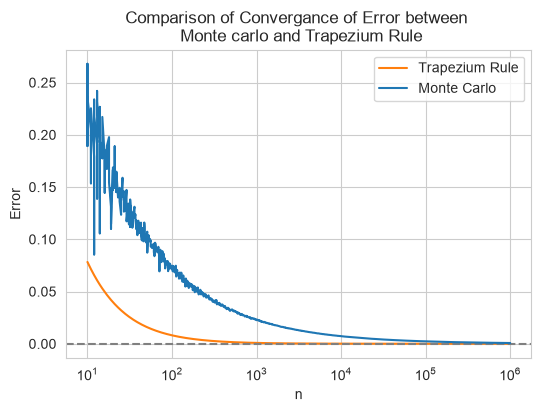

In [ ]:
plt.figure(figsize=(6,4))
plt.tight_layout()

plt.plot(n, mc_errors, label='Monte Carlo')
plt.plot(n, trapezia_errors, label='Trapezium Rule')

plt.title('Comparison of Convergance of Error between \n Monte carlo and Trapezium Rule')

plt.axhline(0, c='grey', ls='--')
plt.legend()
plt.ylabel('Error')
plt.xlabel('n')
plt.xscale('log')